# WICOS Project - Model 3: SVM with RBF Kernel on Spectrogram Images
In Models 1 and 2 the spectrograms are described by hand-crafted features. In this notebook the SVM works directly on the pre-processed spectrogram *images* (128 × 128 pixels), without any knowledge of radar physics. This shows how much the hand-crafted features add.

An image has 16384 pixels, far more than the 960 samples. The dimension is therefore first reduced with principal component analysis (PCA, Lecture 4), as in CodeLab 4. With `whiten=True`, PCA also scales every component to unit variance (PCA-sphering). PCA is part of the `Pipeline`, so it is fitted on the training persons only.

The aim of the project is to recognise a gesture *regardless of the person who performs it*. The 40 samples per person and gesture are cut from one continuous recording, so samples of the same person are very similar. With a random split, the model sees the test person during training and the score is too optimistic.

All models are therefore validated with **leave-one-person-out (LOPO)** cross-validation: the model is trained on five persons and tested on the sixth, once for every person. Hyperparameters are chosen with a second LOPO loop *inside* the five training persons (nested cross-validation), so the test person is never used to choose the model.

In [1]:
# Import packages needed for the lab
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sn
from sklearn import svm
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, LeaveOneGroupOut, PredefinedSplit, cross_val_predict
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay
from sklearn.decomposition import PCA

C:\Users\hawma\AppData\Local\Programs\Python\Python312\Lib\site-packages\seaborn\_statistics.py:32: UserWarning: A NumPy version >=1.22.4 and <2.3.0 is required for this version of SciPy (detected version 2.5.3)
  from scipy.stats import gaussian_kde


In [2]:
SEED = 42
np.random.seed(SEED)

# Folders for the report figures and the results
FIG_DIR = Path("../reports/figures")
RES_DIR = Path("../results")
FIG_DIR.mkdir(exist_ok=True)
RES_DIR.mkdir(exist_ok=True)

## Task 1 - Data Preparation
- Load the pre-processed images: Doppler crop to bins 200-600, floor at -40 dB, scaling to [0, 1] and resizing to 128 × 128 (see `wicos.ipynb`).
- Plot one image per gesture.
- Flatten the images to vectors, so they can be used by PCA and the SVM.

In [3]:
# Load the prepared dataset (created by src/prepare_data.py)
data = np.load("../data/processed/wicos_dataset.npz", allow_pickle=True)

X_img = data["X_img"]                       # (960, 128, 128): Doppler x time, values in [0, 1]
y = data["y"]                               # 0=wave, 1=pinch, 2=swipe, 3=click
persons = data["persons"]                   # person who performed the gesture (A-F)
gestures = list(data["gestures"])

print("Images: " + str(X_img.shape))
print("Label vector y: " + str(y.shape))

Images: (960, 128, 128)
Label vector y: (960,)


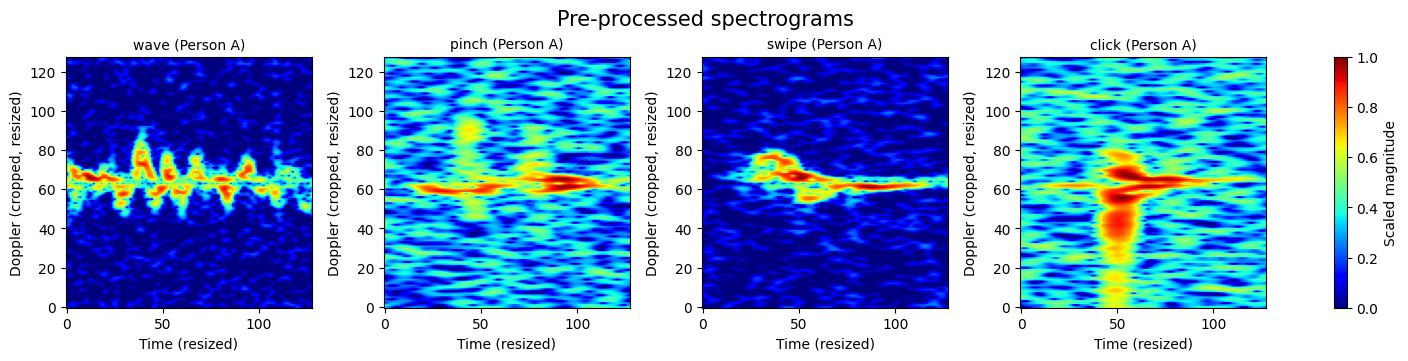

In [4]:
#One pre-processed spectrogram per gesture
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5), constrained_layout=True)
fig.suptitle("Pre-processed spectrograms", fontsize=15)
for j, (ax, g) in enumerate(zip(axes, gestures)):
    i = np.where(y == j)[0][0]
    im = ax.imshow(X_img[i], origin="lower", aspect="auto", cmap="jet", vmin=0, vmax=1)
    ax.set_title(f"{g} (Person {persons[i]})", fontsize=10)
    ax.set_xlabel("Time (resized)")
    ax.set_ylabel("Doppler (cropped, resized)")
fig.colorbar(im, ax=axes, label="Scaled magnitude")
fig.savefig(FIG_DIR / "svm_images_examples.pdf", bbox_inches="tight")
plt.show()

In [5]:
# Flatten the images
X = X_img.reshape(X_img.shape[0], -1)
print("Flattened feature matrix X: " + str(X.shape))

Flattened feature matrix X: (960, 16384)


## Task 2 - Principal component analysis
- Apply `PCA` to the flattened images and plot the cumulative explained variance of the first 200 components.
- Plot (scatter) the first two principal components, coloured by gesture.

This PCA is fitted on all images only to *visualise* the data. In the models below, PCA is refitted inside every training fold.

20 components explain 66.3% of the variance
50 components explain 75.1% of the variance
100 components explain 81.1% of the variance
200 components explain 87.5% of the variance


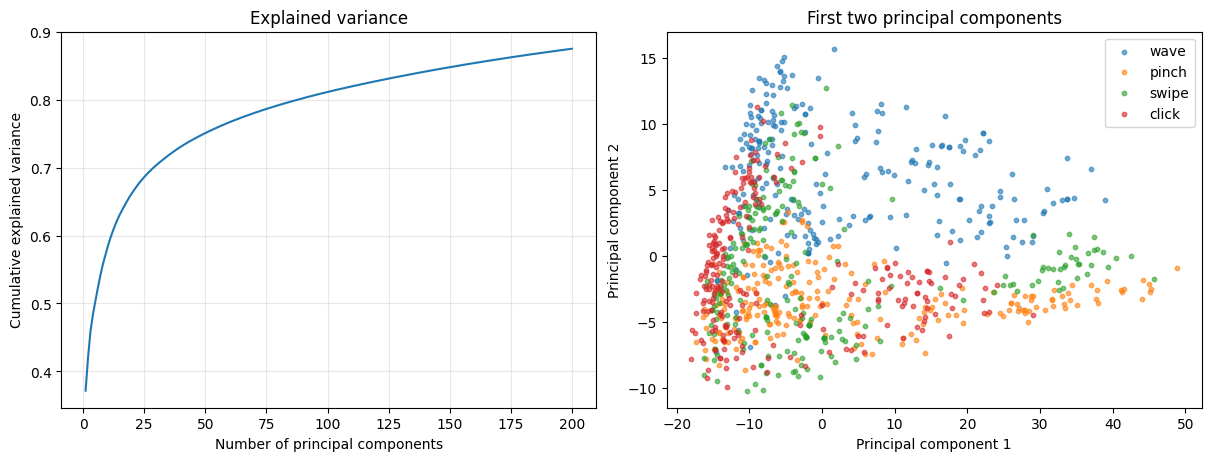

In [6]:
#PCA of all images (visualisation only)
pca = PCA(n_components=200, svd_solver="randomized", random_state=SEED)
X_pca = pca.fit_transform(X)
cum_var = np.cumsum(pca.explained_variance_ratio_)
for n in [20, 50, 100, 200]:
    print(f"{n} components explain {cum_var[n - 1]:.1%} of the variance")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
axes[0].plot(np.arange(1, 201), cum_var)
axes[0].set_xlabel("Number of principal components")
axes[0].set_ylabel("Cumulative explained variance")
axes[0].set_title("Explained variance")
axes[0].grid(alpha=0.3)

for j, g in enumerate(gestures):
    axes[1].scatter(X_pca[y == j, 0], X_pca[y == j, 1], s=10, alpha=0.6, label=g)
axes[1].set_xlabel("Principal component 1")
axes[1].set_ylabel("Principal component 2")
axes[1].set_title("First two principal components")
axes[1].legend()
fig.savefig(FIG_DIR / "svm_images_pca.pdf", bbox_inches="tight")
plt.show()

The function `lopo_scores` computes the accuracy and macro-F1 score for every held-out person. Macro-F1 averages the F1 score of the four gestures, so every gesture counts equally. `print_scores` prints the mean ± standard deviation over the six persons.

In [7]:
def lopo_scores(y_true, y_pred, groups):
    # Accuracy and macro-F1 per held-out person
    rows = []
    for p in np.unique(groups):
        mask = groups == p
        rows.append({
            "person": p,
            "accuracy": accuracy_score(y_true[mask], y_pred[mask]),
            "f1_macro": f1_score(y_true[mask], y_pred[mask], average="macro"),
        })
    return pd.DataFrame(rows)


def print_scores(scores):
    # Mean and standard deviation over the six persons
    print("Accuracy: " + f"{scores.accuracy.mean():.3f} ± {scores.accuracy.std():.3f}")
    print("F1 score (macro): " + f"{scores.f1_macro.mean():.3f} ± {scores.f1_macro.std():.3f}")

In [8]:
def clean(params):
    # Short parameter names and rounded values for printing
    return {k.split("__")[-1]: (float(f"{v:.3g}") if isinstance(v, np.floating) else v) for k, v in params.items()}

## Task 3 - Baseline model
- Develop a pipeline of `PCA` (50 components) and an RBF `SVC` with default parameters (C = 1, γ = 'scale').
- Predict every person with a model trained on the other five persons.
- Calculate and print the accuracy and macro-F1 score.

The pixels all have the same unit (scaled dB in [0, 1]), so no `StandardScaler` is used before PCA.

In [9]:
#Baseline PCA + SVM
clf_base = Pipeline([
    ("pca", PCA(n_components=50, svd_solver="randomized", random_state=SEED)),
    ("clf", svm.SVC(kernel="rbf")),
])

y_pred_base = cross_val_predict(clf_base, X, y, groups=persons, cv=LeaveOneGroupOut())
scores_base = lopo_scores(y, y_pred_base, persons)
print_scores(scores_base)
scores_base

Accuracy: 0.582 ± 0.200
F1 score (macro): 0.559 ± 0.208


,person,accuracy,f1_macro
0,A,0.46250,0.424476
1,B,0.25625,0.234281
2,C,0.76250,0.756625
3,D,0.73750,0.719502
4,E,0.73125,0.718544
5,F,0.54375,0.500701


## Task 4 - Hyperparameter tuning
- Run a grid search over the number of PCA components, whitening and C with LOPO cross-validation on all six persons. γ is kept at 'scale' (1 / (number of features × variance)), which adapts to the number of components and to whitening.
- Plot the training and validation macro-F1 as heat maps.

The scores in this task are used to *study* the hyperparameters; the unbiased estimate follows in Task 5.

In [10]:
#Pipeline and hyperparameter grid
clf = Pipeline([
    ("pca", PCA(svd_solver="randomized", random_state=SEED)),
    ("clf", svm.SVC(kernel="rbf")),
])

param_grid = {
    "pca__n_components": [20, 50, 100],
    "pca__whiten": [False, True],
    "clf__C": [0.1, 1, 10, 100],
}

#Grid search with leave-one-person-out cross-validation
search_all = GridSearchCV(clf, param_grid, cv=LeaveOneGroupOut(), scoring="f1_macro", n_jobs=-1, return_train_score=True)
search_all.fit(X, y, groups=persons)
print("Best parameters: " + str(clean(search_all.best_params_)))
print("Best validation F1 score (macro): " + str(round(search_all.best_score_, 3)))

Best parameters: {'C': 10, 'n_components': 20, 'whiten': True}
Best validation F1 score (macro): 0.617


                   best validation F1 (macro)
param_pca__whiten                            
False                                   0.560
True                                    0.617


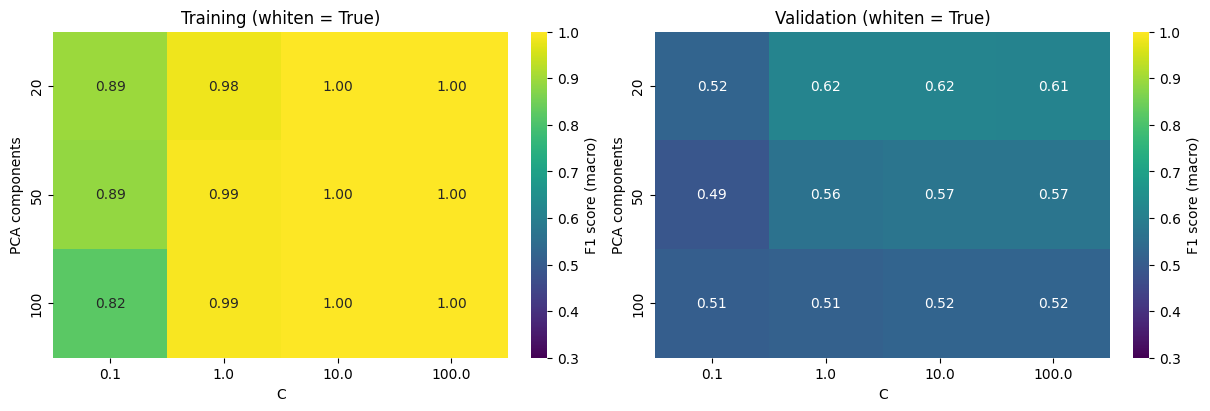

In [11]:
#Heat maps of the training and validation score over the number of components and C
results = pd.DataFrame(search_all.cv_results_)
results = results.astype({"param_pca__n_components": int, "param_clf__C": float, "param_pca__whiten": bool})
best_whiten = results.loc[results.mean_test_score.idxmax(), "param_pca__whiten"]
print(results.groupby("param_pca__whiten").mean_test_score.max().round(3).to_frame("best validation F1 (macro)"))
r = results[results.param_pca__whiten == best_whiten]

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for ax, score, title in zip(axes, ["mean_train_score", "mean_test_score"], ["Training", "Validation"]):
    table = r.pivot_table(index="param_pca__n_components", columns="param_clf__C", values=score)
    sn.heatmap(table, annot=True, fmt=".2f", cmap="viridis", vmin=0.3, vmax=1, ax=ax, cbar_kws={"label": "F1 score (macro)"})
    ax.set_title(f"{title} (whiten = {best_whiten})")
    ax.set_xlabel("C")
    ax.set_ylabel("PCA components")
fig.savefig(FIG_DIR / "svm_images_grid.pdf", bbox_inches="tight")
plt.show()

## Task 5 - Nested leave-one-person-out evaluation
- For every person: tune the number of components, whitening and C with a LOPO grid search on the other five persons, then test the best model once on the held-out person.
- Calculate and print the accuracy and macro-F1 score (mean ± std over the six persons).
- Plot the accuracy per person and the confusion matrix.

In [12]:
#Nested leave-one-person-out
logo = LeaveOneGroupOut()
y_pred_nested = np.zeros_like(y)
best_params = []

for train_idx, test_idx in logo.split(X, y, groups=persons):
    person = persons[test_idx][0]

    # Inner loop: tune the hyperparameters on the five training persons only
    search = GridSearchCV(clf, param_grid, cv=LeaveOneGroupOut(), scoring="f1_macro", n_jobs=-1)
    search.fit(X[train_idx], y[train_idx], groups=persons[train_idx])

    # Outer loop: test once on the held-out person
    y_pred_nested[test_idx] = search.predict(X[test_idx])
    best_params.append({"person": person, **clean(search.best_params_)})
    print(f"Person {person} held out -> best parameters: {best_params[-1]}")

scores_nested = lopo_scores(y, y_pred_nested, persons).merge(pd.DataFrame(best_params), on="person")
scores_nested

Person A held out -> best parameters: {'person': 'A', 'C': 10, 'n_components': 50, 'whiten': True}
Person B held out -> best parameters: {'person': 'B', 'C': 10, 'n_components': 20, 'whiten': True}
Person C held out -> best parameters: {'person': 'C', 'C': 1, 'n_components': 50, 'whiten': True}
Person D held out -> best parameters: {'person': 'D', 'C': 10, 'n_components': 20, 'whiten': True}
Person E held out -> best parameters: {'person': 'E', 'C': 1, 'n_components': 20, 'whiten': True}
Person F held out -> best parameters: {'person': 'F', 'C': 1, 'n_components': 50, 'whiten': False}


,person,accuracy,f1_macro,C,n_components,whiten
0,A,0.48125,0.454482,10,50,True
1,B,0.36875,0.314863,10,20,True
2,C,0.69375,0.683207,1,50,True
3,D,0.61875,0.575966,10,20,True
4,E,0.68750,0.668130,1,20,True
5,F,0.54375,0.500701,1,50,False


In [13]:
#Performance metrics
print("Baseline:")
print_scores(scores_base)
print("Tuned (nested LOPO):")
print_scores(scores_nested)

Baseline:
Accuracy: 0.582 ± 0.200
F1 score (macro): 0.559 ± 0.208
Tuned (nested LOPO):
Accuracy: 0.566 ± 0.127
F1 score (macro): 0.533 ± 0.140


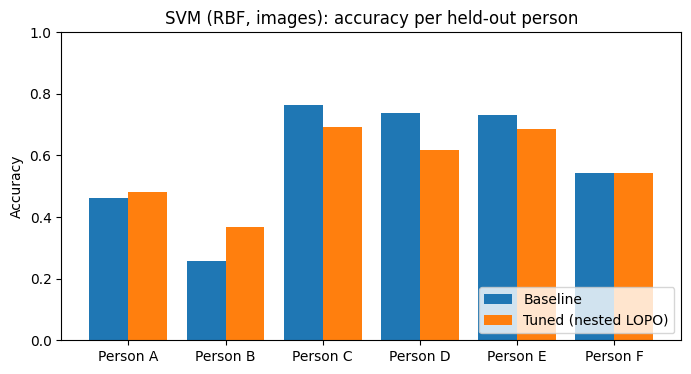

In [14]:
#Accuracy per held-out person: baseline vs tuned model
x = np.arange(len(scores_nested))

plt.figure(figsize=(8, 4))
plt.bar(x - 0.2, scores_base.accuracy, width=0.4, label="Baseline")
plt.bar(x + 0.2, scores_nested.accuracy, width=0.4, label="Tuned (nested LOPO)")
plt.xticks(x, ["Person " + p for p in scores_nested.person])
plt.ylim(0, 1)
plt.ylabel("Accuracy")
plt.title("SVM (RBF, images): accuracy per held-out person")
plt.legend(loc="lower right")
plt.savefig(FIG_DIR / "svm_images_per_person.pdf", bbox_inches="tight")
plt.show()

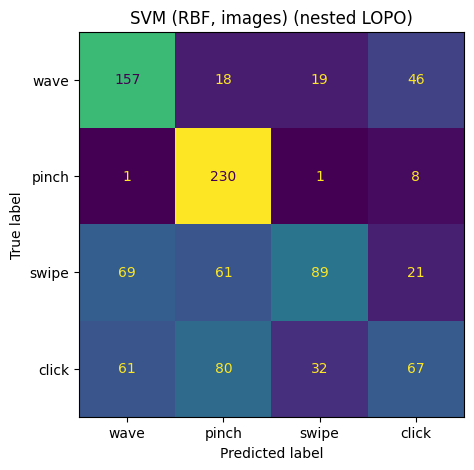

In [15]:
#Confusion matrix of the tuned model, summed over the six held-out persons
fig, ax = plt.subplots(figsize=(5, 5))
ConfusionMatrixDisplay.from_predictions(y, y_pred_nested, display_labels=gestures, ax=ax, colorbar=False)
ax.set_title("SVM (RBF, images) (nested LOPO)")
fig.savefig(FIG_DIR / "svm_images_confusion_matrix.pdf", bbox_inches="tight")
plt.show()

## Task 6 - Comparison with a random split
The data exploration notebook (`wicos.ipynb`) uses a random, stratified 80/20 split. To show why we validate per person, the same model is tuned with the random 5-fold cross-validation of that notebook and tested on its random 20% test set.

- Tune the model with the predefined random folds (`cv_fold`) on the training set.
- Test it on the random test set and compare the score with the LOPO result.

In [16]:
#Random split: tune with the random 5-fold CV, test on the random 20% test set
idx_train, idx_test, cv_fold = data["idx_train"], data["idx_test"], data["cv_fold"]

search_rs = GridSearchCV(clf, param_grid, cv=PredefinedSplit(cv_fold[idx_train]), scoring="f1_macro", n_jobs=-1)
search_rs.fit(X[idx_train], y[idx_train])
y_pred_rs = search_rs.predict(X[idx_test])

accuracy_rs = accuracy_score(y[idx_test], y_pred_rs)
f1_rs = f1_score(y[idx_test], y_pred_rs, average="macro")
print("Best parameters: " + str(clean(search_rs.best_params_)))
print("Accuracy: " + str(round(accuracy_rs, 3)))
print("F1 score (macro): " + str(round(f1_rs, 3)))

Best parameters: {'C': 10, 'n_components': 100, 'whiten': False}
Accuracy: 0.969
F1 score (macro): 0.969


In [17]:
#Random split vs leave-one-person-out
comparison = pd.DataFrame({
    "Accuracy": [accuracy_rs, scores_nested.accuracy.mean()],
    "F1 score (macro)": [f1_rs, scores_nested.f1_macro.mean()],
}, index=["Random 80/20 split", "Leave-one-person-out (mean)"])
comparison.round(3)

,Accuracy,F1 score (macro)
Random 80/20 split,0.969,0.969
Leave-one-person-out (mean),0.566,0.533


## Task 7 - Save the results
The per-person scores and a one-line summary are saved in `results/`, so all models can be compared in one table.

In [18]:
#Save the results
scores_nested.to_csv(RES_DIR / "svm_rbf_images_lopo.csv", index=False)

summary = pd.DataFrame([{
    "model": "SVM RBF (images, PCA)",
    "lopo_accuracy_mean": scores_nested.accuracy.mean(),
    "lopo_accuracy_std": scores_nested.accuracy.std(),
    "lopo_f1_mean": scores_nested.f1_macro.mean(),
    "lopo_f1_std": scores_nested.f1_macro.std(),
    "random_split_accuracy": accuracy_rs,
    "random_split_f1": f1_rs,
}])
summary.to_csv(RES_DIR / "svm_rbf_images_summary.csv", index=False)
summary.round(3)

,model,lopo_accuracy_mean,lopo_accuracy_std,lopo_f1_mean,lopo_f1_std,random_split_accuracy,random_split_f1
0,"SVM RBF (images, PCA)",0.566,0.127,0.533,0.14,0.969,0.969
